In [117]:
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

In [142]:
nt = 500
nx = 51
ny = 51
nu = 0.2
dt = 0.001

dx = 2/(nx-1)
dy = 2/(ny-1)

x  = np.linspace(0,2,nx)
y = np.linspace(0,2,ny)


In [143]:
comb = np.zeros((nx,ny))
comb.shape

(51, 51)

In [144]:
u = np.zeros((ny,nx))
v = np.zeros((ny,nx))

nu = np.zeros((ny,nx))
vn = np.zeros((ny,nx))

uf = np.zeros((nt,ny,nx))
vf = np.zeros((nt,ny,nx))


In [145]:
u = np.ones((ny,nx))
v = np.ones((ny,nx)) 
uf = np.ones((nt,ny,nx))
vf = np.ones((nt,ny,nx))

u[int(0.75/dy):int(1.25/dy+1),int(0.75/dy):int(1.25/dy+1)] = 5

v[int(0.75/dy):int(1.25/dy+1),int(0.75/dy):int(1.25/dy+1)] = 5

uf[0,int(0.75/dy):int(1.25/dy+1),int(0.75/dy):int(1.25/dy+1)] = 5

vf[0,int(0.75/dy):int(1.25/dy+1),int(0.75/dy):int(1.25/dy+1)] = 5

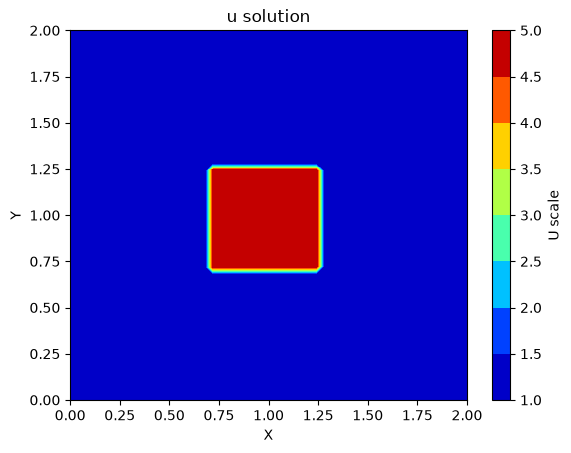

In [81]:
x,y = np.meshgrid(x,y)

plt.Figure(figsize=(8,6))
contour = plt.contourf(x,y,u[:],cmap="jet")
plt.title("u solution")
plt.xlabel("X")
plt.ylabel("Y")
colorbar = plt.colorbar(contour)
colorbar.set_label("U scale")

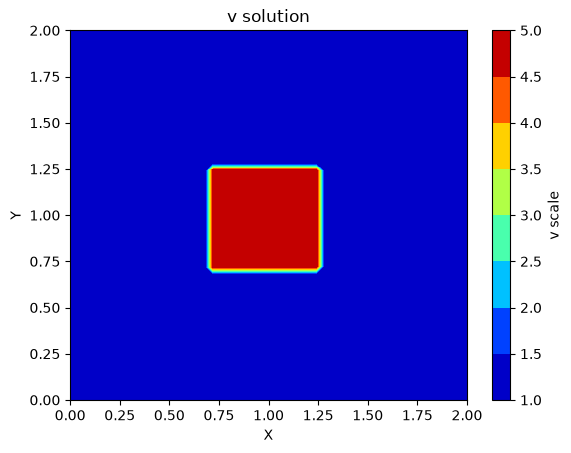

In [66]:
x,y = np.meshgrid(x,y)

plt.Figure(figsize=(8,6))
contour = plt.contourf(x,y,v[:],cmap="jet")
plt.title("v solution")
plt.xlabel("X")
plt.ylabel("Y")
colorbar = plt.colorbar(contour)
colorbar.set_label("v scale")

In [151]:
# Correction: viscosity coefficient
nu = -0.2

# Store initial conditions
uf[0, :, :] = u.copy()
vf[0, :, :] = v.copy()

for n in range(1, nt):

    un = u.copy()
    vn = v.copy()

    for i in range(1, nx-1):
        for j in range(1, ny-1):

            # Burgers equation for u
            u[j,i] = (
                un[j,i]
                - un[j,i] * dt/dx * (un[j,i] - un[j,i-1])
                - vn[j,i] * dt/dy * (un[j,i] - un[j-1,i])
                + nu * dt/dx**2 * (
                    un[j,i+1] - 2*un[j,i] + un[j,i-1]
                )
                + nu * dt/dy**2 * (
                    un[j+1,i] - 2*un[j,i] + un[j-1,i]
                )
            )

            # Burgers equation for v
            v[j,i] = (
                vn[j,i]
                - un[j,i] * dt/dx * (vn[j,i] - vn[j,i-1])
                - vn[j,i] * dt/dy * (vn[j,i] - vn[j-1,i])
                + nu * dt/dx**2 * (
                    vn[j,i+1] - 2*vn[j,i] + vn[j,i-1]
                )
                + nu * dt/dy**2 * (
                    vn[j+1,i] - 2*vn[j,i] + vn[j-1,i]
                )
            )

    # Boundary conditions
    u[0, :] = 1
    u[-1, :] = 1
    u[:, 0] = 1
    u[:, -1] = 1

    v[0, :] = 1
    v[-1, :] = 1
    v[:, 0] = 1
    v[:, -1] = 1

    # Store velocity fields
    uf[n, :, :] = u.copy()
    vf[n, :, :] = v.copy()

C:\Users\safir\AppData\Local\Temp\ipykernel_24480\3197491611.py:19: RuntimeWarning: overflow encountered in scalar multiply
  - un[j,i] * dt/dx * (un[j,i] - un[j,i-1])
C:\Users\safir\AppData\Local\Temp\ipykernel_24480\3197491611.py:20: RuntimeWarning: overflow encountered in scalar multiply
  - vn[j,i] * dt/dy * (un[j,i] - un[j-1,i])
C:\Users\safir\AppData\Local\Temp\ipykernel_24480\3197491611.py:18: RuntimeWarning: invalid value encountered in scalar subtract
  un[j,i]
C:\Users\safir\AppData\Local\Temp\ipykernel_24480\3197491611.py:32: RuntimeWarning: overflow encountered in scalar multiply
  - un[j,i] * dt/dx * (vn[j,i] - vn[j,i-1])
C:\Users\safir\AppData\Local\Temp\ipykernel_24480\3197491611.py:33: RuntimeWarning: overflow encountered in scalar multiply
  - vn[j,i] * dt/dy * (vn[j,i] - vn[j-1,i])
C:\Users\safir\AppData\Local\Temp\ipykernel_24480\3197491611.py:31: RuntimeWarning: invalid value encountered in scalar subtract
  vn[j,i]
C:\Users\safir\AppData\Local\Temp\ipykernel_24480\

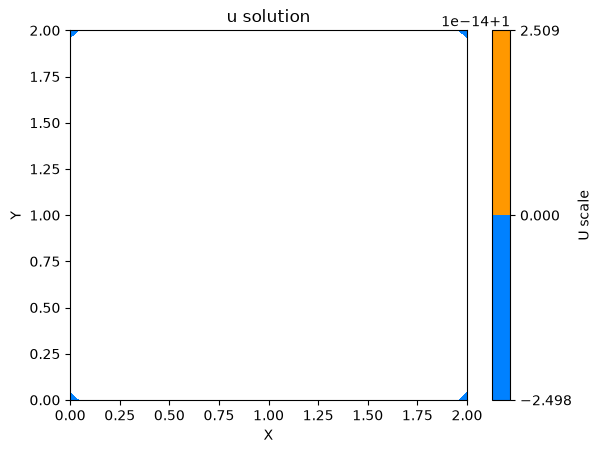

In [152]:
X,Y = np.meshgrid(x,y)

plt.Figure(figsize=(8,6))
contour = plt.contourf(X,Y,v[:],cmap="jet")
plt.title("u solution")
plt.xlabel("X")
plt.ylabel("Y")
colorbar = plt.colorbar(contour)
colorbar.set_label("U scale")

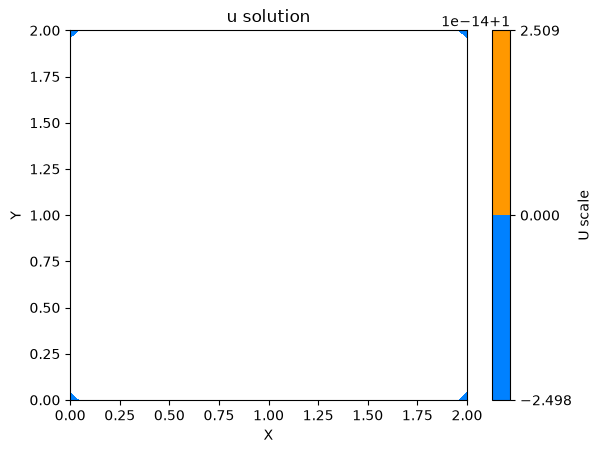

In [153]:
X,Y = np.meshgrid(x,y)
# set the time as like
u= uf[10, :, :]
plt.Figure(figsize=(8,6))
contour = plt.contourf(X,Y,u[:],cmap="jet")
plt.title("u solution")
plt.xlabel("X")
plt.ylabel("Y")
colorbar = plt.colorbar(contour)
colorbar.set_label("U scale")